# A/B-тест: перенос «ворот» в мобильной игре Cookie Cats

**Контекст.** Cookie Cats — мобильная игра-головоломка «три в ряд». На определённых уровнях игрока встречают «ворота»: дальше можно пройти, только подождав или заплатив. Команда проверяет гипотезу: если перенести первые ворота с **30-го уровня на 40-й**, игроки дольше будут получать удовольствие от игры и чаще возвращаться.

**Дизайн эксперимента.** Новые игроки случайно распределялись в две группы:
- `gate_30` — контроль (ворота на 30-м уровне);
- `gate_40` — тест (ворота на 40-м уровне).

**Метрики:**
| Роль | Метрика | Описание |
|---|---|---|
| Основная | `retention_7` | игрок вернулся в игру через 7 дней после установки |
| Дополнительная | `retention_1` | вернулся через 1 день |
| Барьерная (guardrail) | `sum_gamerounds` | число сыгранных раундов за первые 14 дней |

**Данные:** [Cookie Cats A/B test](https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing) (Tactile Entertainment / DataCamp), 90 189 игроков.

**План:** проверка данных → проверка корректности сплита (SRM) → анализ метрик (z-тест, доверительные интервалы, bootstrap) → мощность теста → решение.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
COLORS = {"gate_30": "#4C72B0", "gate_40": "#DD8452"}
ALPHA = 0.05
rng = np.random.default_rng(42)

## 1. Проверка данных

In [2]:
df = pd.read_csv("data/cookie_cats.csv")
print(f"Игроков: {len(df):,} | уникальных userid: {df.userid.nunique():,} | пропусков: {df.isna().sum().sum()}")
df.head()

Игроков: 90,189 | уникальных userid: 90,189 | пропусков: 0

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.groupby("version").agg(
    players=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    rounds_mean=("sum_gamerounds", "mean"),
    rounds_median=("sum_gamerounds", "median"),
    rounds_max=("sum_gamerounds", "max"),
)

,players,retention_1,retention_7,rounds_mean,rounds_median,rounds_max
version,,,,,,
gate_30,44700,0.448188,0.190201,52.456264,17.0,49854
gate_40,45489,0.442283,0.182000,51.298776,16.0,2640


Топ-5 значений: [49854, 2961, 2640, 2438, 2294]
Доля игроков, не сыгравших ни одного раунда: 4.4%

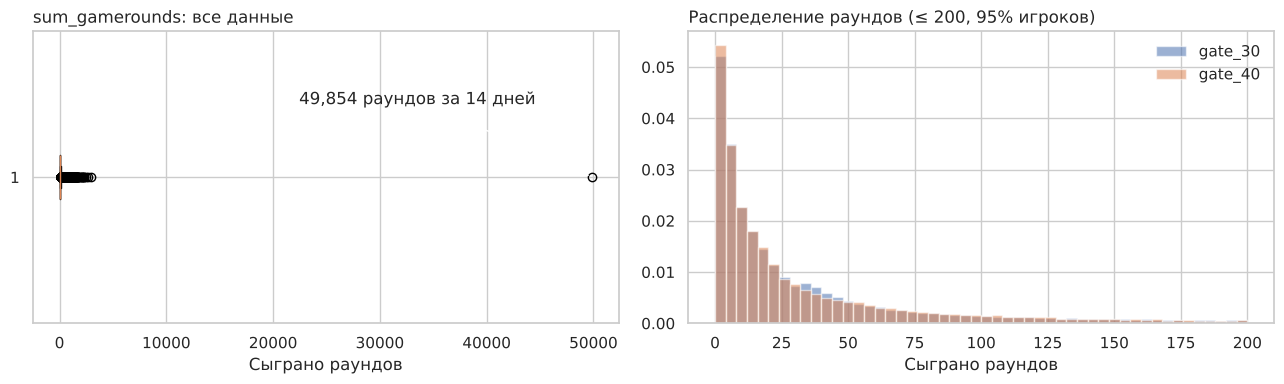

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(df.sum_gamerounds, orientation="horizontal")
axes[0].set_title("sum_gamerounds: все данные", loc="left")
axes[0].set_xlabel("Сыграно раундов")
top = df.sum_gamerounds.nlargest(5)
axes[0].annotate(f"{top.iloc[0]:,} раундов за 14 дней", xy=(top.iloc[0], 1), xytext=(top.iloc[0] * 0.45, 1.25),
                 arrowprops=dict(arrowstyle="->"))
clip = df[df.sum_gamerounds <= 200]
for v, g in clip.groupby("version"):
    axes[1].hist(g.sum_gamerounds, bins=50, alpha=.55, label=v, color=COLORS[v], density=True)
axes[1].set_title("Распределение раундов (≤ 200, 95% игроков)", loc="left")
axes[1].set_xlabel("Сыграно раундов"); axes[1].legend(frameon=False)
fig.tight_layout()
print("Топ-5 значений:", top.tolist())
print(f"Доля игроков, не сыгравших ни одного раунда: {(df.sum_gamerounds == 0).mean():.1%}")

Один игрок «сыграл» **49 854 раунда за 14 дней** (≈150 раундов в час без сна), а следующее значение — 2 961. Это почти наверняка бот или ошибка логирования, поэтому для метрики раундов исключаем эту запись. Распределение раундов сильно скошено (медиана 16, среднее 52), поэтому для неё нужны устойчивые методы: тест Манна–Уитни и bootstrap.

In [5]:
df = df[df.sum_gamerounds < 49_854].reset_index(drop=True)
print(f"Осталось игроков: {len(df):,}")

Осталось игроков: 90,188

## 2. Проверка корректности сплита (SRM)

Ожидаемое распределение 50/50. Если фактические размеры групп значимо отличаются от ожидаемых (**sample ratio mismatch**), значит, в механизме сплитования или логирования что-то сломано, и результатам теста нельзя слепо доверять.

In [6]:
counts = df.version.value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts)
print(counts.to_string())
print(f"\nДоля gate_40: {counts['gate_40'] / counts.sum():.2%}")
print(f"χ²-тест на SRM: χ² = {chi2:.2f}, p-value = {p_srm:.4f}")
print("⚠️  SRM обнаружен: распределение статистически отличается от 50/50" if p_srm < 0.01 else "SRM не обнаружен")

version
gate_30    44699
gate_40    45489

Доля gate_40: 50.44%
χ²-тест на SRM: χ² = 6.92, p-value = 0.0085
⚠️  SRM обнаружен: распределение статистически отличается от 50/50

In [7]:
zero = df.assign(zero_rounds=df.sum_gamerounds == 0).groupby("version").zero_rounds.agg(["sum", "mean"])
zero.columns = ["игроков с 0 раундов", "доля"]
excess = counts["gate_40"] - counts["gate_30"]
excess_zero = zero.loc["gate_40", "игроков с 0 раундов"] - zero.loc["gate_30", "игроков с 0 раундов"]
print(f"Лишних игроков в gate_40: {excess}, из них не сыгравших ни раунда: {excess_zero}")
zero

Лишних игроков в gate_40: 790, из них не сыгравших ни раунда: 120

,игроков с 0 раундов,доля
version,,
gate_30,1937,0.043334
gate_40,2057,0.045220


In [8]:
nz = df[df.sum_gamerounds > 0].version.value_counts().sort_index()
_, p_srm_nz = stats.chisquare(nz)
print(f"SRM среди игроков, сыгравших хотя бы 1 раунд: p-value = {p_srm_nz:.4f}")

SRM среди игроков, сыгравших хотя бы 1 раунд: p-value = 0.0225

**⚠️ Вывод по SRM.** В тестовой группе на 790 игроков больше ожидаемого (50,44% вместо 50%), p-value = 0.0085. Отклонение небольшое, но статистически значимое. Проверка показала, что оно **не объясняется** игроками, установившими игру и ни разу не сыгравшими (на них приходится только 120 из 790 «лишних»), и сохраняется среди активных игроков (p = 0.02).

Найти причину по этим данным нельзя: в них нет времени распределения, платформы и версии приложения. В реальной работе следующим шагом было бы сообщить команде разработки о возможной ошибке в сплитовании или логировании. **Дальнейшие выводы делаем с этой оговоркой**: перекос мал по сравнению с эффектом, но полностью исключить систематическое смещение нельзя.

## 3. Основная метрика: retention_7

Используем двусторонний **z-тест для разницы долей** (выборки большие, наблюдения независимы) и строим 95% доверительный интервал для разницы. Уровень значимости α = 0.05.

In [9]:
def ztest_proportions(df, metric, control="gate_30", test="gate_40"):
    a, b = df.loc[df.version == control, metric], df.loc[df.version == test, metric]
    n1, n2, x1, x2 = len(a), len(b), a.sum(), b.sum()
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    p_value = 2 * stats.norm.sf(abs(z))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    zc = stats.norm.ppf(1 - ALPHA / 2)
    return pd.Series({
        "контроль, %": 100 * p1, "тест, %": 100 * p2,
        "разница, п.п.": 100 * (p2 - p1),
        "95% ДИ: от": 100 * (p2 - p1 - zc * se), "95% ДИ: до": 100 * (p2 - p1 + zc * se),
        "отн. изменение, %": 100 * (p2 / p1 - 1),
        "z": z, "p-value": p_value,
    }, name=metric)

results = pd.DataFrame([ztest_proportions(df, m) for m in ["retention_7", "retention_1"]])
results.round(4)

,"контроль, %","тест, %","разница, п.п.",95% ДИ: от,95% ДИ: до,"отн. изменение, %",z,p-value
retention_7,19.0183,18.2000,-0.8183,-1.3263,-0.3103,-4.3028,-3.1574,0.0016
retention_1,44.8198,44.2283,-0.5915,-1.2403,0.0572,-1.3198,-1.7871,0.0739


### Bootstrap: распределение разницы retention

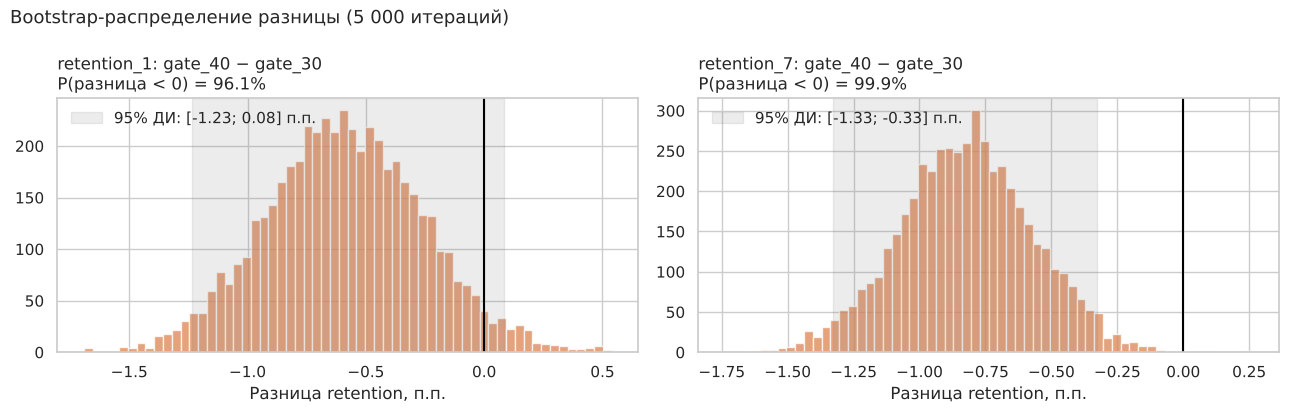

In [10]:
def bootstrap_stat(x, func=np.mean, n_boot=5000, chunk=250):
    x = np.asarray(x, dtype=float)
    out = [func(x[rng.integers(0, len(x), size=(min(chunk, n_boot - i), len(x)))], axis=1)
           for i in range(0, n_boot, chunk)]
    return np.concatenate(out)

boot = {}
for m in ["retention_1", "retention_7"]:
    b30 = bootstrap_stat(df.loc[df.version == "gate_30", m])
    b40 = bootstrap_stat(df.loc[df.version == "gate_40", m])
    boot[m] = (b40 - b30) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, ["retention_1", "retention_7"]):
    d = boot[m]
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.hist(d, bins=60, color=COLORS["gate_40"], alpha=.75)
    ax.axvline(0, c="black", lw=1.5)
    ax.axvspan(lo, hi, color="grey", alpha=.15, label=f"95% ДИ: [{lo:.2f}; {hi:.2f}] п.п.")
    ax.set_title(f"{m}: gate_40 − gate_30\nP(разница < 0) = {(d < 0).mean():.1%}", loc="left")
    ax.set_xlabel("Разница retention, п.п."); ax.legend(frameon=False, loc="upper left")
fig.suptitle("Bootstrap-распределение разницы (5 000 итераций)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/bootstrap_retention.png", dpi=120, bbox_inches="tight")

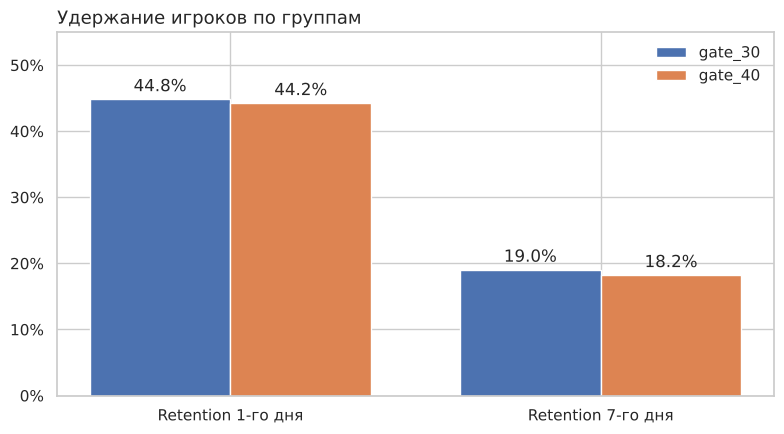

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
for i, v in enumerate(["gate_30", "gate_40"]):
    vals = [results.loc[m, "контроль, %" if v == "gate_30" else "тест, %"] for m in ["retention_1", "retention_7"]]
    bars = ax.bar(x + (i - .5) * 0.38, vals, width=0.38, label=v, color=COLORS[v])
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xticks(x, ["Retention 1-го дня", "Retention 7-го дня"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 55)
ax.legend(frameon=False)
ax.set_title("Удержание игроков по группам", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/retention_by_group.png", dpi=120, bbox_inches="tight")

**Вывод по удержанию.**
- **retention_7** (основная метрика) **значимо снизился**: 19,02% → 18,20% (−0,82 п.п., −4,3% относительно контроля). 95% ДИ [−1,33; −0,31] п.п. не включает ноль, p-value = 0.0016. По bootstrap вероятность того, что тест хуже контроля, равна 99,9%.
- **retention_1** тоже ниже (−0,59 п.п.), но разница **не значима** (p = 0.074, ДИ включает 0).

Гипотеза «поздние ворота удержат игроков лучше» **не подтвердилась**, эффект противоположный. Правдоподобное объяснение: ворота на 30-м уровне вынуждают сделать паузу, и игрок не «пресыщается» игрой и с большей вероятностью вернётся через неделю.

## 4. Барьерная метрика: сыгранные раунды

Распределение сильно скошено, поэтому используем **тест Манна–Уитни** и bootstrap доверительные интервалы для среднего и медианы.

In [12]:
r30 = df.loc[df.version == "gate_30", "sum_gamerounds"].to_numpy()
r40 = df.loc[df.version == "gate_40", "sum_gamerounds"].to_numpy()
mw = stats.mannwhitneyu(r30, r40, alternative="two-sided")

def boot_ci(a, b, func, n_boot=3000):
    diff = bootstrap_stat(b, func, n_boot) - bootstrap_stat(a, func, n_boot)
    return np.percentile(diff, [2.5, 97.5])

rounds = pd.DataFrame({
    "gate_30": [r30.mean(), np.median(r30)],
    "gate_40": [r40.mean(), np.median(r40)],
}, index=["среднее", "медиана"])
rounds["разница"] = rounds.gate_40 - rounds.gate_30
ci_mean, ci_med = boot_ci(r30, r40, np.mean), boot_ci(r30, r40, np.median)
rounds["95% ДИ (bootstrap)"] = [f"[{ci_mean[0]:.2f}; {ci_mean[1]:.2f}]", f"[{ci_med[0]:.0f}; {ci_med[1]:.0f}]"]
print(f"Манн–Уитни: p-value = {mw.pvalue:.4f}")
rounds.round(2)

Манн–Уитни: p-value = 0.0509

,gate_30,gate_40,разница,95% ДИ (bootstrap)
среднее,51.34,51.3,-0.04,[-1.41; 1.33]
медиана,17.00,16.0,-1.00,[-1; 0]


**Вывод.** Активность игроков за 14 дней **не изменилась**: средние почти равны (51,3 раунда), 95% ДИ разницы [−1,4; +1,3] включает ноль, а тест Манна–Уитни незначим (p = 0.051). Перенос ворот не увеличил вовлечённость, хотя у игроков группы gate_40 было на 10 бесплатных уровней больше.

## 5. Мощность теста

Проверим, мог ли тест вообще обнаружить эффект разумного размера. **MDE** (minimum detectable effect) — минимальная разница, которую тест с такой выборкой находит с мощностью 80% при α = 0.05.

In [13]:
def mde(p, n_per_group, alpha=ALPHA, power=0.8):
    return (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) * np.sqrt(2 * p * (1 - p) / n_per_group)

def power_at(p1, p2, n_per_group, alpha=ALPHA):
    se = np.sqrt(p1 * (1 - p1) / n_per_group + p2 * (1 - p2) / n_per_group)
    zc = stats.norm.ppf(1 - alpha / 2)
    return stats.norm.sf(zc - abs(p2 - p1) / se) + stats.norm.cdf(-zc - abs(p2 - p1) / se)

n = counts.min()
power_tbl = pd.DataFrame({
    "базовый уровень, %": [100 * results.loc[m, "контроль, %"] / 100 for m in ["retention_7", "retention_1"]],
    "MDE, п.п.": [100 * mde(results.loc[m, "контроль, %"] / 100, n) for m in ["retention_7", "retention_1"]],
    "наблюдаемая разница, п.п.": results["разница, п.п."].values,
}, index=["retention_7", "retention_1"])
power_tbl["|разница| > MDE?"] = power_tbl["наблюдаемая разница, п.п."].abs() > power_tbl["MDE, п.п."]
power_tbl.round(2)

,"базовый уровень, %","MDE, п.п.","наблюдаемая разница, п.п.",|разница| > MDE?
retention_7,19.02,0.74,-0.82,True
retention_1,44.82,0.93,-0.59,False


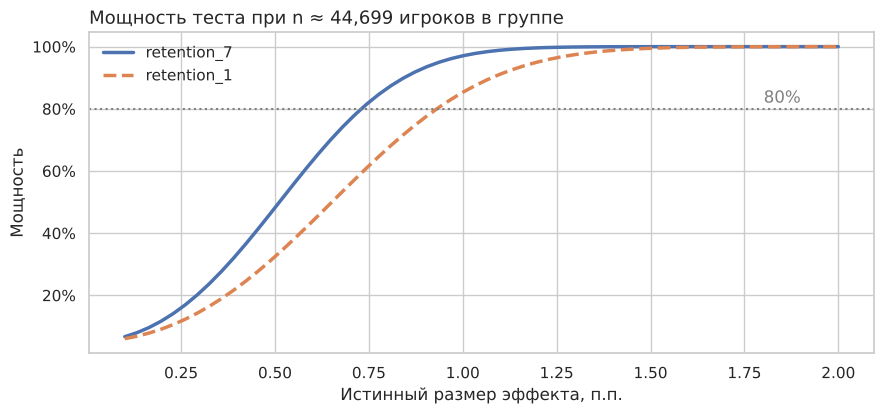

In [14]:
effects = np.linspace(0.1, 2, 60)
fig, ax = plt.subplots(figsize=(9, 4.3))
for m, ls in [("retention_7", "-"), ("retention_1", "--")]:
    p1 = results.loc[m, "контроль, %"] / 100
    ax.plot(effects, [power_at(p1, p1 - e / 100, n) for e in effects], ls=ls, lw=2.5, label=m)
ax.axhline(0.8, c="grey", ls=":", lw=1.5); ax.text(1.9, 0.82, "80%", ha="right", color="grey")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Истинный размер эффекта, п.п."); ax.set_ylabel("Мощность")
ax.set_title(f"Мощность теста при n ≈ {n:,} игроков в группе", loc="left", fontsize=13)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("images/power_curve.png", dpi=120, bbox_inches="tight")

**Вывод.** Тест достаточно мощный: при 80% мощности он находит изменение retention_7 от **≈0,74 п.п.**, а наблюдаемый эффект (−0,82 п.п.) больше этого порога. Для retention_1 MDE ≈ 0,93 п.п., поэтому разница в −0,59 п.п. могла остаться незамеченной: отсутствие значимости здесь не доказывает отсутствие эффекта.

## 6. Итог и рекомендация

| Метрика | gate_30 | gate_40 | Разница | Значимо? |
|---|---|---|---|---|
| **retention_7** (основная) | 19,02% | 18,20% | −0,82 п.п. [−1,33; −0,31] | ✅ да, p = 0.002 |
| retention_1 | 44,82% | 44,23% | −0,59 п.п. [−1,24; +0,06] | ❌ нет, p = 0.074 |
| Раунды за 14 дней (среднее) | 51,3 | 51,3 | −0,04 [−1,4; +1,3] | ❌ нет |
| Корректность сплита (SRM) | — | — | 50,44% в тесте | ⚠️ p = 0.009 |

### Решение: **не внедрять** перенос ворот на 40-й уровень, оставить на 30-м.

Перенос ворот снижает долю игроков, которые возвращаются через неделю, и при этом не даёт роста активности. На каждые 10 000 новых игроков это ≈ 80 игроков меньше, вернувшихся на 7-й день.

**Следующие шаги:**
1. Передать команде разработки находку по SRM и проверить механизм сплитования до следующих тестов.
2. Проверить обратную гипотезу: ворота **раньше** 30-го уровня (например, на 25-м) могут улучшить retention.
3. В следующих тестах добавить метрики монетизации (покупки на воротах) и более длинное удержание (retention_30), чтобы оценить влияние на выручку.